# Task 2 - Customer Segmentation Analysis

**Data Analytics Internship | Customer Purchase Dataset**

This notebook takes a year of raw transaction data and turns it into an
actionable customer segmentation model:

1. **Load** the customer purchase dataset
2. **Clean & preprocess** the data (types, missing values, duplicates, invalid records)
3. **Calculate RFM** - *Recency*, *Frequency* and *Monetary value* for every customer
4. **Score & label** customers with rule-based RFM segments
5. **Cluster** customers with **K-Means** (k chosen with the elbow + silhouette method)
6. **Visualise** the segments
7. **Identify** high-value, regular and low-value customers
8. **Derive** business insights and recommendations

Tools: Python 3, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn, Jupyter Notebook.
All numbers and insights below are computed live from the dataset - nothing is hard-coded.

In [1]:
%matplotlib inline

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (9, 5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": False,
})


def find_project_root(start=None):
    """Walk up from the current folder until data/ and notebooks/ are found."""
    p = Path(start or Path.cwd()).resolve()
    for candidate in [p, *p.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    return p


ROOT = find_project_root()
DATA_PATH = ROOT / "data" / "customer_purchases.csv"
OUTPUTS = ROOT / "outputs"
CHARTS_DIR = OUTPUTS / "charts"
REPORTS_DIR = OUTPUTS / "reports"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

RUPEE = "\u20b9"


def money(x):
    return "{cur}{v:,.0f}".format(cur=RUPEE, v=x)


def save_chart(name):
    """Save the active figure to outputs/charts/."""
    plt.savefig(CHARTS_DIR / name, dpi=150, bbox_inches="tight", facecolor="white")
    print("saved: outputs/charts/" + name)


print("Project root :", ROOT)
print("Dataset      :", DATA_PATH.relative_to(ROOT))
print("Charts dir   :", CHARTS_DIR.relative_to(ROOT))

Project root : C:\Users\SACHIN.K\OneDrive\Desktop\DA task-2
Dataset      : data\customer_purchases.csv
Charts dir   : outputs\charts


## 1. Load the dataset

`data/customer_purchases.csv` holds one row per **transaction** for a full year
(Jan - Dec 2025): customer id, date, product, category, quantity, unit price,
discount, net amount, payment method, region and channel.

In [2]:
raw = pd.read_csv(DATA_PATH)

print("Rows      : {:,}".format(raw.shape[0]))
print("Columns   : {}".format(raw.shape[1]))
print("Customers : {:,}".format(raw["Customer_ID"].nunique()))
print("Columns   : {}".format(list(raw.columns)))
raw.head()

Rows      : 4,002
Columns   : 12
Customers : 520
Columns   : ['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Discount', 'Total_Amount', 'Payment_Method', 'Region', 'Channel']


,Transaction_ID,Customer_ID,Transaction_Date,Product,Category,Quantity,Unit_Price,Discount,Total_Amount,Payment_Method,Region,Channel
0,TXN-102391,CUST-0330,2025-02-19,Denim Jeans,Clothing,1,1459.35,0.00,1459.35,UPI,East,Online
1,TXN-101404,CUST-0182,2025-08-17,Shampoo 650ml,Beauty,2,362.31,0.05,688.39,UPI,North,Online
2,TXN-103778,CUST-0498,2025-03-28,Tablet 10 inch,Electronics,2,16090.37,0.15,27353.63,Cash,West,In-Store
3,TXN-100208,CUST-0030,2025-11-01,Cotton Shirt,Clothing,1,920.72,0.00,920.72,COD,West,Online
4,TXN-101679,CUST-0221,2025-01-18,Tablet 10 inch,Electronics,2,15526.14,0.00,31052.28,UPI,West,In-Store


## 2. Data quality inspection

Before any analysis we check what is wrong with the raw data: data types,
missing values, duplicates, invalid records and stray whitespace.

In [3]:
print("=== Data types ===")
print(raw.dtypes.to_string())

print("\n=== Shape ===  {} rows x {} columns".format(*raw.shape))
print("=== Exact duplicate rows ===  {}".format(int(raw.duplicated().sum())))

missing = raw.isna().sum()
print("\n=== Missing values ===")
if (missing > 0).any():
    print(missing[missing > 0].to_string())
    print("Total missing cells: {}".format(int(missing.sum())))
else:
    print("none")

print("\n=== Sample values per column ===")
for c in raw.columns:
    sample = list(raw[c].dropna().astype(str).unique()[:4])
    print("  {:<18} {}".format(c, sample))

=== Data types ===
Transaction_ID          str
Customer_ID             str
Transaction_Date        str
Product                 str
Category                str
Quantity              int64
Unit_Price          float64
Discount            float64
Total_Amount            str
Payment_Method          str
Region                  str
Channel                 str

=== Shape ===  4002 rows x 12 columns
=== Exact duplicate rows ===  76

=== Missing values ===
Customer_ID         39
Transaction_Date    29
Unit_Price          19
Total_Amount        23
Payment_Method      40
Region              51
Channel             32
Total missing cells: 233

=== Sample values per column ===
  Transaction_ID     ['TXN-102391', 'TXN-101404', 'TXN-103778', 'TXN-100208']
  Customer_ID        ['CUST-0330', 'CUST-0182', 'CUST-0498', 'CUST-0030']
  Transaction_Date   ['2025-02-19', '2025-08-17', '2025-03-28', '2025-11-01']
  Product            ['Denim Jeans', 'Shampoo 650ml', 'Tablet 10 inch', 'Cotton Shirt']
  Category 

In [4]:
print("=== Rows with Quantity <= 0 ===   {}".format(int((pd.to_numeric(raw['Quantity'], errors='coerce') <= 0).sum())))
print("=== Rows with Discount outside 0-1 ===   {}".format(int(((pd.to_numeric(raw['Discount'], errors='coerce') < 0) | (pd.to_numeric(raw['Discount'], errors='coerce') > 1)).sum())))
print("=== Rows with non-numeric Total_Amount ===   {}".format(int(pd.to_numeric(raw['Total_Amount'].astype('string').str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce').isna().sum())))
print("=== Rows with missing / unparseable dates ===   {}".format(int(pd.to_datetime(raw['Transaction_Date'], errors='coerce').isna().sum())))


def count_whitespace(series):
    s = series.astype("string").fillna("")
    return int((s.str.strip() != s).sum())


ws = sum(count_whitespace(raw[c]) for c in ["Channel", "Region", "Payment_Method"])
print("=== Values with leading/trailing whitespace ===   {}".format(ws))

=== Rows with Quantity <= 0 ===   6
=== Rows with Discount outside 0-1 ===   4
=== Rows with non-numeric Total_Amount ===   23
=== Rows with missing / unparseable dates ===   35
=== Values with leading/trailing whitespace ===   68


## 3. Data cleaning & preprocessing

| # | Step | Why it matters |
| --- | --- | --- |
| 1 | Trim whitespace from text columns | `" In-Store "` must match `"In-Store"` |
| 2 | Standardise `Region`, `Channel`, `Payment_Method` | Mixed casing (`UPI` / `upi`) splits groups |
| 3 | Convert types: dates -> datetime, money/qty -> numeric | Calculations need real types |
| 4 | Drop rows missing essentials (customer, date, qty, price, amount) | RFM cannot be computed without them |
| 5 | Fill optional gaps (`Region`, `Payment_Method`, `Channel`) with `Unknown` | Keep otherwise valid orders |
| 6 | Remove exact duplicate transactions | Duplicates inflate revenue and frequency |
| 7 | Remove invalid records (qty/price/amount <= 0, discount outside 0-1) | Physically impossible values |

In [5]:
TEXT_COLS = ["Transaction_ID", "Customer_ID", "Product", "Category",
             "Payment_Method", "Region", "Channel"]
ESSENTIAL = ["Customer_ID", "Transaction_Date", "Quantity", "Unit_Price", "Total_Amount"]
OPTIONAL_TEXT = ["Region", "Payment_Method", "Channel"]
CANON_PAYMENTS = {"UPI": "UPI", "CARD": "Card", "CASH": "Cash", "WALLET": "Wallet", "COD": "COD"}


def clean_transactions(df):
    """Return (cleaned dataframe, step-by-step audit dataframe)."""
    df = df.copy()
    report = []

    def record(step, before):
        report.append({"Step": step, "Rows_Removed": before - len(df), "Rows_Remaining": len(df)})

    # 1 - whitespace
    before = len(df)
    for c in TEXT_COLS:
        df[c] = df[c].astype("string").str.strip()
    record("Trimmed whitespace from text columns", before)

    # 2 - standardise categoricals
    df["Region"] = df["Region"].str.title()
    df["Channel"] = df["Channel"].str.title()
    df["Payment_Method"] = df["Payment_Method"].str.upper().map(CANON_PAYMENTS)
    record("Standardised Region / Channel / Payment_Method values", before)

    # 3 - types
    amount_text = df["Total_Amount"].astype("string").str.replace(r"[^0-9.\-]", "", regex=True)
    df["Total_Amount"] = pd.to_numeric(amount_text, errors="coerce").astype("float64")
    df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
    df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce").astype("float64")
    df["Discount"] = pd.to_numeric(df["Discount"], errors="coerce").astype("float64")
    df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], errors="coerce")
    record("Converted types (dates -> datetime, money/qty -> numeric)", before)

    # 4 - essential values
    before = len(df)
    df = df.dropna(subset=ESSENTIAL)
    record("Dropped rows missing essential values (customer, date, qty, price, amount)", before)

    # 5 - optional values
    for c in OPTIONAL_TEXT:
        df[c] = df[c].fillna("Unknown")
    df["Discount"] = df["Discount"].fillna(0.0)
    record("Filled optional gaps with 'Unknown' / 0.0 discount", before)

    # 6 - duplicates
    before = len(df)
    df = df.drop_duplicates()
    record("Removed exact duplicate transactions", before)

    # 7 - invalid records
    before = len(df)
    bad = ((df["Quantity"] <= 0) | (df["Unit_Price"] <= 0) | (df["Total_Amount"] <= 0) |
           (df["Discount"] < 0) | (df["Discount"] > 1))
    df = df[~bad]
    record("Removed invalid records (qty/price/amount <= 0, discount outside 0-1)", before)

    df = df.sort_values(["Transaction_Date", "Transaction_ID"]).reset_index(drop=True)
    return df, pd.DataFrame(report)


cleaned, cleaning_report = clean_transactions(raw)
cleaning_report

,Step,Rows_Removed,Rows_Remaining
0,Trimmed whitespace from text columns,0,4002
1,Standardised Region / Channel / Payment_Method...,0,4002
2,"Converted types (dates -> datetime, money/qty ...",0,4002
3,Dropped rows missing essential values (custome...,115,3887
4,Filled optional gaps with 'Unknown' / 0.0 disc...,115,3887
5,Removed exact duplicate transactions,76,3811
6,Removed invalid records (qty/price/amount <= 0...,14,3797


In [6]:
def count_missing(frame):
    return int(frame.isna().sum().sum())


audit = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing cells", "Duplicate rows",
               "Distinct customers", "Distinct products"],
    "Before": [len(raw), raw.shape[1], count_missing(raw), int(raw.duplicated().sum()),
               raw["Customer_ID"].nunique(), raw["Product"].nunique()],
    "After": [len(cleaned), cleaned.shape[1], count_missing(cleaned), int(cleaned.duplicated().sum()),
              cleaned["Customer_ID"].nunique(), cleaned["Product"].nunique()],
})
print(audit.to_string(index=False))
print()
print(cleaning_report.to_string(index=False))

report_path = REPORTS_DIR / "data_cleaning_report.txt"
with open(report_path, "w", encoding="utf-8") as fh:
    fh.write("Customer Purchase Data - Cleaning Report\n")
    fh.write("=" * 72 + "\n\n")
    fh.write("Source : data/customer_purchases.csv\n")
    fh.write("Rows before cleaning : {:,}\n".format(len(raw)))
    fh.write("Rows after cleaning  : {:,}\n".format(len(cleaned)))
    fh.write("Rows removed         : {:,}\n\n".format(len(raw) - len(cleaned)))
    fh.write(cleaning_report.to_string(index=False))
    fh.write("\n")
print("\nsaved: outputs/reports/data_cleaning_report.txt")

cleaned.to_csv(OUTPUTS / "cleaned_transactions.csv", index=False)
print("saved: outputs/cleaned_transactions.csv")

            Metric  Before  After
              Rows    4002   3797
           Columns      12     12
     Missing cells     233      0
    Duplicate rows      76      0
Distinct customers     520    520
 Distinct products      27     27

                                                                      Step  Rows_Removed  Rows_Remaining
                                      Trimmed whitespace from text columns             0            4002
                     Standardised Region / Channel / Payment_Method values             0            4002
                 Converted types (dates -> datetime, money/qty -> numeric)             0            4002
Dropped rows missing essential values (customer, date, qty, price, amount)           115            3887
                        Filled optional gaps with 'Unknown' / 0.0 discount           115            3887
                                      Removed exact duplicate transactions            76            3811
     Removed invalid recor

## 4. Exploratory data analysis

Quick look at the business before segmenting: how much is sold, when, in which
categories and through which channel.

In [7]:
date_min = cleaned["Transaction_Date"].min()
date_max = cleaned["Transaction_Date"].max()
total_revenue = cleaned["Total_Amount"].sum()

kpis = [
    ("Transactions", "{:,}".format(cleaned["Transaction_ID"].nunique())),
    ("Customers", "{:,}".format(cleaned["Customer_ID"].nunique())),
    ("Period", "{} - {}".format(date_min.strftime("%d %b %Y"), date_max.strftime("%d %b %Y"))),
    ("Revenue", money(total_revenue)),
    ("Average order value", money(cleaned["Total_Amount"].mean())),
    ("Average basket size", "{:.1f} items".format(cleaned["Quantity"].mean())),
    ("Distinct products", str(cleaned["Product"].nunique())),
    ("Categories", str(cleaned["Category"].nunique())),
]
print("=== Key performance indicators ===")
for name, value in kpis:
    print("  {:<22} {}".format(name, value))

=== Key performance indicators ===
  Transactions           3,797
  Customers              520
  Period                 01 Jan 2025 - 26 Dec 2025
  Revenue                ₹28,691,305
  Average order value    ₹7,556
  Average basket size    2.3 items
  Distinct products      27
  Categories             6


saved: outputs/charts/01_monthly_transactions_and_revenue.png


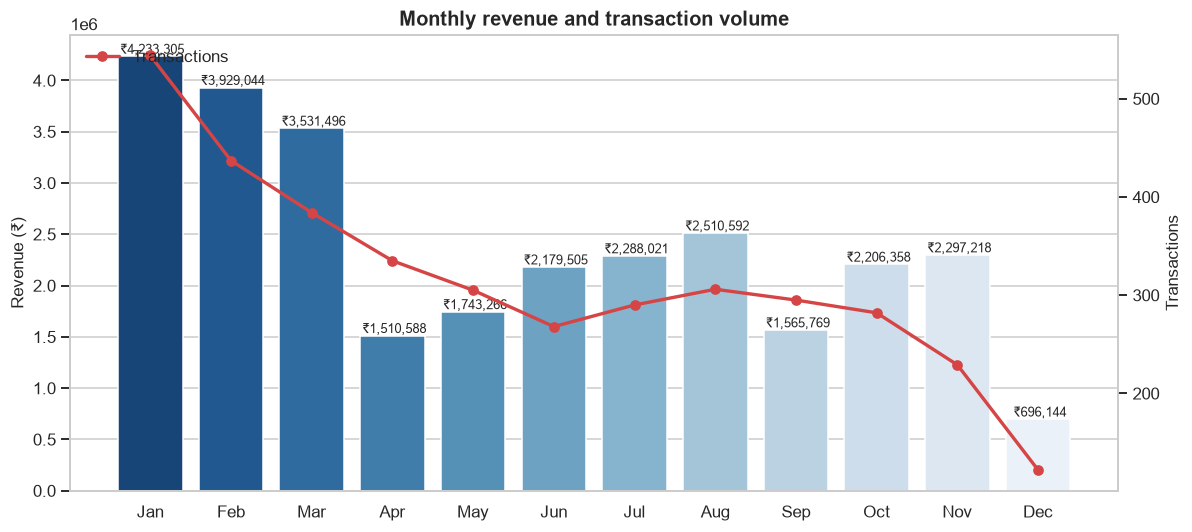

In [8]:
monthly = (
    cleaned.assign(Month=cleaned["Transaction_Date"].dt.to_period("M").dt.to_timestamp())
    .groupby("Month")
    .agg(Revenue=("Total_Amount", "sum"), Transactions=("Transaction_ID", "nunique"))
    .reset_index()
)
monthly["Label"] = monthly["Month"].dt.strftime("%b")

fig, ax1 = plt.subplots(figsize=(11, 5))
sns.barplot(data=monthly, x="Label", y="Revenue", hue="Label", palette="Blues_r",
            legend=False, ax=ax1)
ax1.set_ylabel("Revenue ({})".format(RUPEE))
ax1.set_xlabel("")
ax1.set_title("Monthly revenue and transaction volume")

ax2 = ax1.twinx()
ax2.plot(monthly["Label"], monthly["Transactions"], color="#d64545", marker="o",
         lw=2.2, label="Transactions")
ax2.set_ylabel("Transactions")
ax2.grid(False)
ax2.legend(loc="upper left")

for i, v in enumerate(monthly["Revenue"]):
    ax1.text(i, v, " " + money(v), ha="center", va="bottom", fontsize=8.5)

fig.tight_layout()
save_chart("01_monthly_transactions_and_revenue.png")
plt.show()

saved: outputs/charts/02_revenue_by_category.png


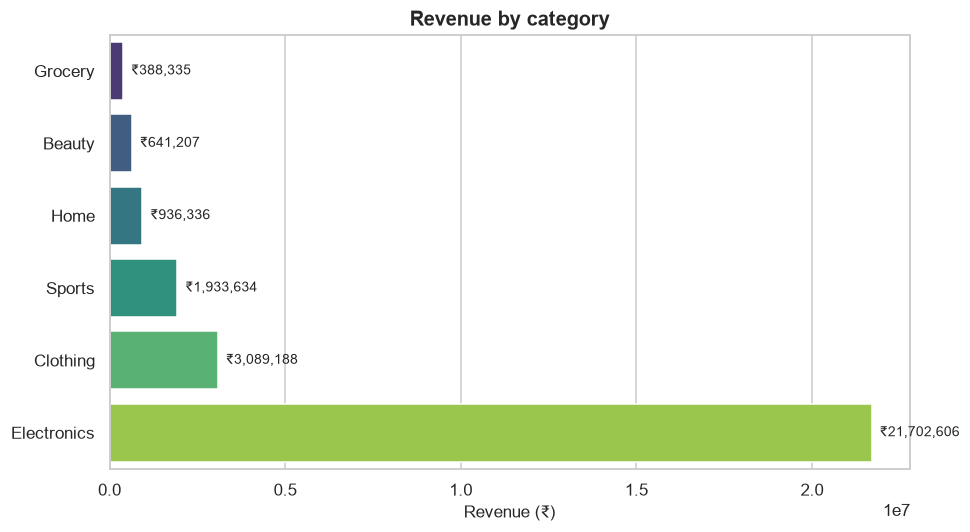

In [9]:
by_category = (
    cleaned.groupby("Category")
    .agg(Revenue=("Total_Amount", "sum"), Transactions=("Transaction_ID", "nunique"),
         Customers=("Customer_ID", "nunique"))
    .sort_values("Revenue")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=by_category, y="Category", x="Revenue", hue="Category",
            palette="viridis", legend=False, ax=ax)
ax.set_title("Revenue by category")
ax.set_xlabel("Revenue ({})".format(RUPEE))
ax.set_ylabel("")
for i, v in enumerate(by_category["Revenue"]):
    ax.text(v, i, "  " + money(v), va="center", fontsize=9)

fig.tight_layout()
save_chart("02_revenue_by_category.png")
plt.show()

saved: outputs/charts/03_revenue_by_channel_and_region.png


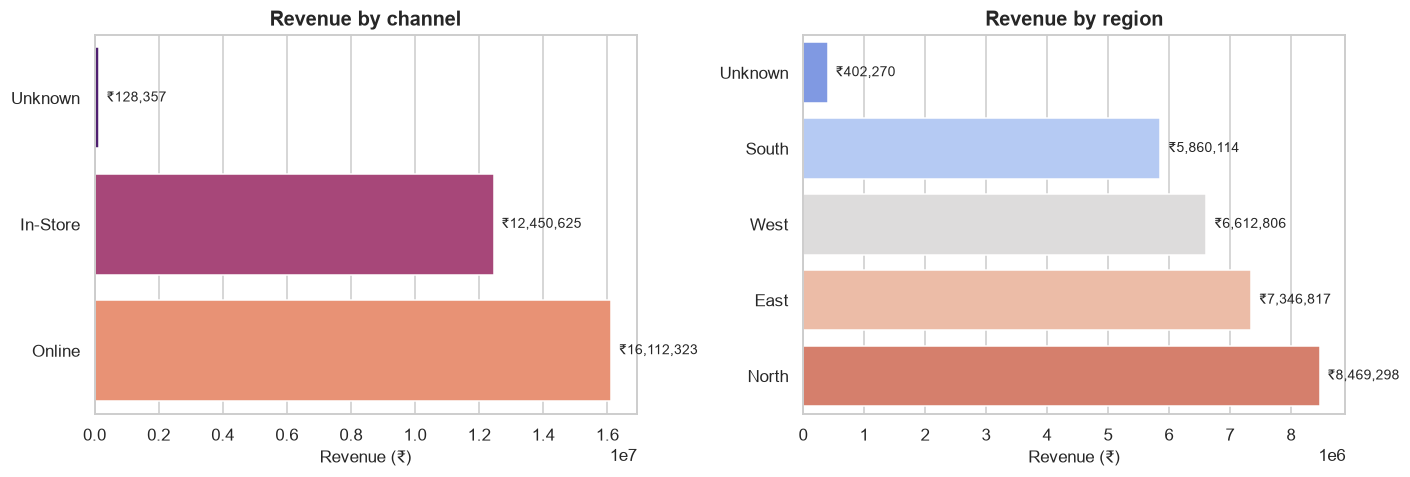

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

by_channel = cleaned.groupby("Channel")["Total_Amount"].sum().sort_values()
by_region = cleaned.groupby("Region")["Total_Amount"].sum().sort_values()

sns.barplot(x=by_channel.values, y=by_channel.index, hue=by_channel.index,
            palette="magma", legend=False, ax=axes[0])
axes[0].set_title("Revenue by channel")
axes[0].set_xlabel("Revenue ({})".format(RUPEE))
axes[0].set_ylabel("")
for i, v in enumerate(by_channel.values):
    axes[0].text(v, i, "  " + money(v), va="center", fontsize=9)

sns.barplot(x=by_region.values, y=by_region.index, hue=by_region.index,
            palette="coolwarm", legend=False, ax=axes[1])
axes[1].set_title("Revenue by region")
axes[1].set_xlabel("Revenue ({})".format(RUPEE))
axes[1].set_ylabel("")
for i, v in enumerate(by_region.values):
    axes[1].text(v, i, "  " + money(v), va="center", fontsize=9)

fig.tight_layout()
save_chart("03_revenue_by_channel_and_region.png")
plt.show()

## 5. RFM metrics

For every customer we compute:

| Metric | Definition | Good |
| --- | --- | --- |
| **Recency** | Days between the last purchase and the snapshot date (day after the last transaction) | *low* |
| **Frequency** | Number of distinct transactions | *high* |
| **Monetary** | Total spend | *high* |

Plus supporting fields: first/last purchase dates, average order value and the
number of distinct products bought.

In [11]:
snapshot = cleaned["Transaction_Date"].max() + pd.Timedelta(days=1)

rfm = (
    cleaned.groupby("Customer_ID")
    .agg(
        Recency=("Transaction_Date", lambda s: (snapshot - s.max()).days),
        Frequency=("Transaction_ID", "nunique"),
        Monetary=("Total_Amount", "sum"),
        First_Purchase=("Transaction_Date", "min"),
        Last_Purchase=("Transaction_Date", "max"),
        Avg_Order_Value=("Total_Amount", "mean"),
        Distinct_Products=("Product", "nunique"),
        Categories=("Category", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown"),
    )
    .reset_index()
)

rfm["Tenure_Days"] = (snapshot - rfm["First_Purchase"]).dt.days

print("Snapshot date :", snapshot.strftime("%d %b %Y"))
print("Customers     : {:,}".format(len(rfm)))
rfm.head()

Snapshot date : 27 Dec 2025
Customers     : 520


,Customer_ID,Recency,Frequency,Monetary,First_Purchase,Last_Purchase,Avg_Order_Value,Distinct_Products,Categories,Tenure_Days
0,CUST-0001,51,4,22671.55,2025-05-08,2025-11-06,5667.887500,4,Clothing,233
1,CUST-0002,330,1,123039.84,2025-01-31,2025-01-31,123039.840000,1,Electronics,330
2,CUST-0003,218,4,230786.04,2025-02-08,2025-05-23,57696.510000,4,Electronics,322
3,CUST-0004,17,3,3889.15,2025-10-13,2025-12-10,1296.383333,3,Grocery,75
4,CUST-0005,75,12,67314.01,2025-02-27,2025-10-13,5609.500833,7,Home,303


In [12]:
print("=== RFM distribution ===")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(1).to_string())
print("\nSkewness (high = long tail):")
print(rfm[["Recency", "Frequency", "Monetary"]].skew().round(2).to_string())
print("\nTotal revenue captured by RFM: {}".format(money(rfm["Monetary"].sum())))

=== RFM distribution ===
       Recency  Frequency  Monetary
count    520.0      520.0     520.0
mean     136.0        7.3   55175.6
std      114.4        7.3   95077.5
min        1.0        1.0     324.9
25%       34.0        2.0    6183.8
50%       99.0        4.0   16592.6
75%      248.2        9.0   58245.2
max      355.0       30.0  718485.0

Skewness (high = long tail):
Recency      0.52
Frequency    1.61
Monetary     3.14

Total revenue captured by RFM: ₹28,691,305


## 6. RFM distributions

Recency, Frequency and Monetary are all skewed - a handful of customers spend a
lot more than the rest. This is exactly why K-Means needs a log transform and
standardisation before clustering.

saved: outputs/charts/04_rfm_distributions.png


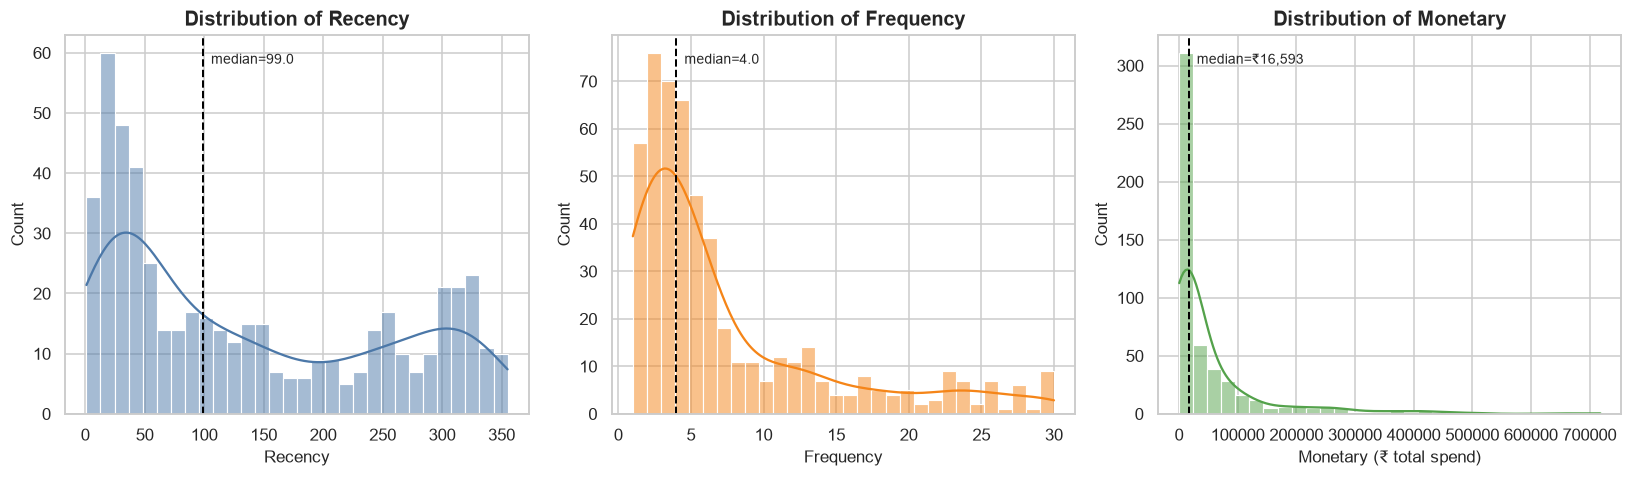

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
metrics = ["Recency", "Frequency", "Monetary"]
colors = ["#4c78a8", "#f58518", "#54a24b"]

for ax, metric, color in zip(axes, metrics, colors):
    sns.histplot(rfm[metric], bins=30, kde=True, color=color, ax=ax, edgecolor="white")
    median = rfm[metric].median()
    ax.axvline(median, color="black", ls="--", lw=1.3)
    ax.set_title("Distribution of " + metric)
    ax.set_xlabel(metric)
    if metric == "Monetary":
        ax.set_xlabel("Monetary ({} total spend)".format(RUPEE))
    ax.text(median, ax.get_ylim()[1] * 0.95, "  median=" + (money(median) if metric == "Monetary" else str(round(median, 1))),
            fontsize=9, va="top")

fig.tight_layout()
save_chart("04_rfm_distributions.png")
plt.show()

saved: outputs/charts/05_frequency_vs_monetary.png


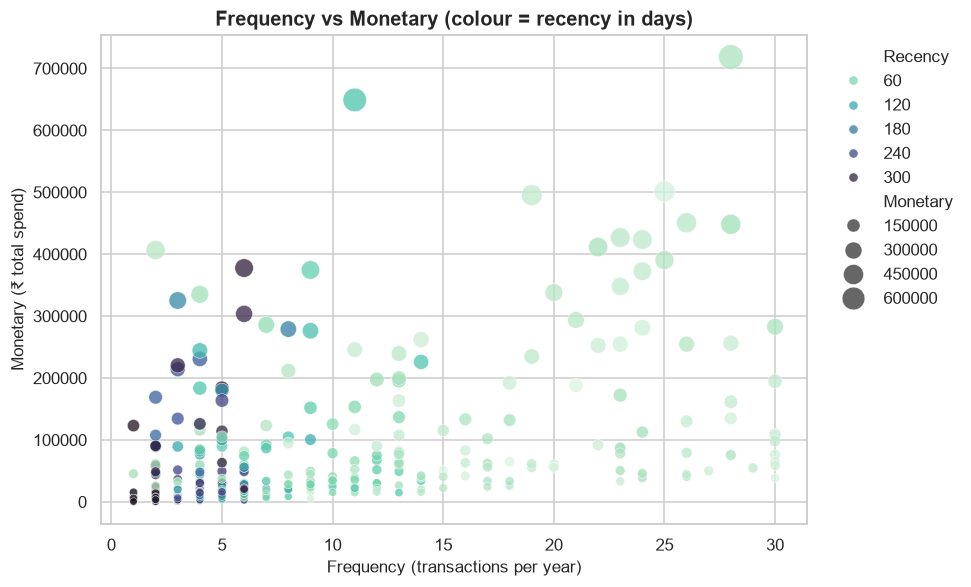

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Recency",
                size="Monetary", sizes=(25, 260), palette="mako_r", alpha=0.75, ax=ax)
ax.set_title("Frequency vs Monetary (colour = recency in days)")
ax.set_xlabel("Frequency (transactions per year)")
ax.set_ylabel("Monetary ({} total spend)".format(RUPEE))
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

fig.tight_layout()
save_chart("05_frequency_vs_monetary.png")
plt.show()

## 7. Rule-based RFM scoring and segments

Each metric is split into quartiles (1 = worst, 4 = best):

- `R_Score` 4 = most recent quartile
- `F_Score` / `M_Score` 4 = highest quartile
- `RFM_Score` = R + F + M (3 - 12)

Clear business rules then map every customer to a named segment:
**Champions, Loyal Customers, Potential Loyalists, Recent Customers,
At Risk, Need Attention, Hibernating, Lost**.

In [15]:
def add_rfm_scores(frame):
    frame = frame.copy()
    frame["R_Score"] = pd.qcut(frame["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
    frame["F_Score"] = pd.qcut(frame["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
    frame["M_Score"] = pd.qcut(frame["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
    frame["RFM_Score"] = frame[["R_Score", "F_Score", "M_Score"]].sum(axis=1)
    frame["RFM_Segment"] = [
        assign_rfm_segment(r, f, m)
        for r, f, m in zip(frame["R_Score"], frame["F_Score"], frame["M_Score"])
    ]
    return frame


def assign_rfm_segment(r, f, m):
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if r >= 3 and f >= 3:
        return "Loyal Customers"
    if r >= 4 and m >= 3:
        return "Potential Loyalists"
    if r >= 4:
        return "Recent / New Customers"
    if f >= 3 and m >= 3:
        return "At Risk (High Value)"
    if r == 3:
        return "Need Attention"
    if r == 2 and f >= 3:
        return "At Risk"
    if r == 2:
        return "Hibernating"
    return "Lost"


rfm = add_rfm_scores(rfm)

print("RFM score ranges: R {}-{} | F {}-{} | M {}-{}".format(
    rfm["R_Score"].min(), rfm["R_Score"].max(),
    rfm["F_Score"].min(), rfm["F_Score"].max(),
    rfm["M_Score"].min(), rfm["M_Score"].max()))
print("\nCustomers per RFM segment:")
print(rfm["RFM_Segment"].value_counts().to_string())

RFM score ranges: R 1-4 | F 1-4 | M 1-4

Customers per RFM segment:
RFM_Segment
Loyal Customers           127
Lost                      112
Hibernating                87
Champions                  52
At Risk (High Value)       44
Recent / New Customers     38
Need Attention             37
At Risk                    17
Potential Loyalists         6


saved: outputs/charts/06_customers_per_rfm_segment.png


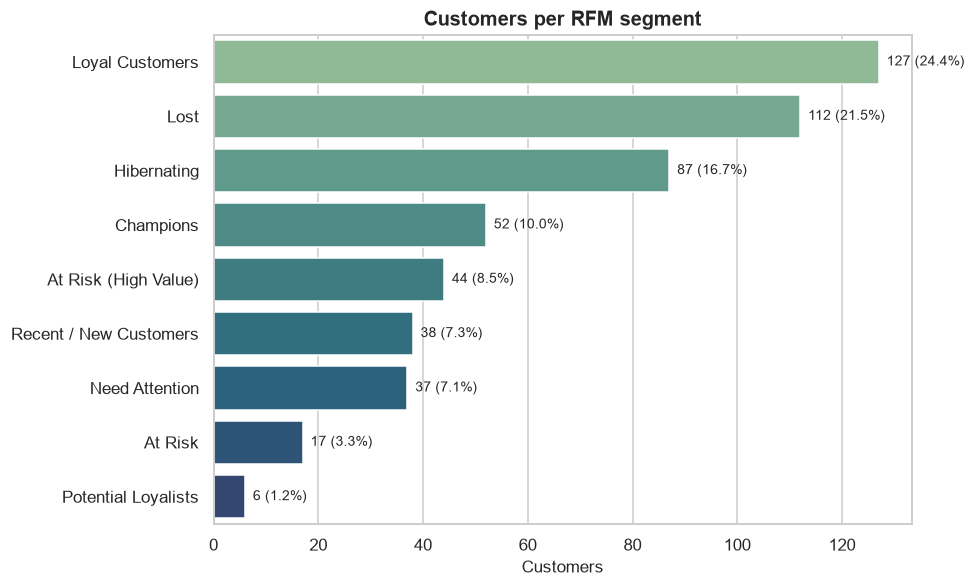

In [16]:
seg_order = rfm["RFM_Segment"].value_counts().index.tolist()
seg_counts = rfm["RFM_Segment"].value_counts().reindex(seg_order)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=seg_counts.values, y=seg_counts.index, hue=seg_counts.index,
            palette="crest", legend=False, ax=ax)
ax.set_title("Customers per RFM segment")
ax.set_xlabel("Customers")
ax.set_ylabel("")
total = len(rfm)
for i, v in enumerate(seg_counts.values):
    ax.text(v, i, "  {:,} ({:.1f}%)".format(v, 100 * v / total), va="center", fontsize=9)

fig.tight_layout()
save_chart("06_customers_per_rfm_segment.png")
plt.show()

In [17]:
seg_summary = (
    rfm.groupby("RFM_Segment")
    .agg(Customers=("Customer_ID", "count"),
         Avg_Recency=("Recency", "mean"),
         Avg_Frequency=("Frequency", "mean"),
         Avg_Monetary=("Monetary", "mean"),
         Total_Revenue=("Monetary", "sum"))
    .reset_index()
    .sort_values("Avg_Monetary", ascending=False)
)
seg_summary["Share_of_Customers_%"] = (100 * seg_summary["Customers"] / seg_summary["Customers"].sum()).round(1)
seg_summary["Share_of_Revenue_%"] = (100 * seg_summary["Total_Revenue"] / seg_summary["Total_Revenue"].sum()).round(1)
seg_summary["Avg_Recency"] = seg_summary["Avg_Recency"].round(0)
seg_summary["Avg_Frequency"] = seg_summary["Avg_Frequency"].round(1)
seg_summary["Avg_Monetary"] = seg_summary["Avg_Monetary"].round(0)

seg_summary.to_csv(OUTPUTS / "rfm_segment_summary.csv", index=False)
print("saved: outputs/rfm_segment_summary.csv\n")
seg_summary.to_markdown(index=False)

saved: outputs/rfm_segment_summary.csv



'| RFM_Segment            |   Customers |   Avg_Recency |   Avg_Frequency |   Avg_Monetary |    Total_Revenue |   Share_of_Customers_% |   Share_of_Revenue_% |\n|:-----------------------|------------:|--------------:|----------------:|---------------:|-----------------:|-----------------------:|---------------------:|\n| Champions              |          52 |            18 |            21   |         186536 |      9.69989e+06 |                   10   |                 33.8 |\n| Potential Loyalists    |           6 |            19 |             2.5 |          91780 | 550683           |                    1.2 |                  1.9 |\n| Loyal Customers        |         127 |            48 |            12.6 |          76975 |      9.77585e+06 |                   24.4 |                 34.1 |\n| At Risk (High Value)   |          44 |           208 |             6   |          67343 |      2.96307e+06 |                    8.5 |                 10.3 |\n| Need Attention         |          37 

## 8. K-Means clustering

**Is K-Means suitable here?** Yes - we have ~500 customers with three
well-defined numeric behaviours, no labels, and the goal is to find naturally
occurring groups. Two preparation steps are mandatory first:

1. **Log transform** (`log1p`) - Frequency and Monetary are heavily right-skewed
2. **StandardScaler** - recency (0-350 days) must not dominate frequency (1-30)

`k` is not guessed: the **elbow curve** and the **silhouette score** decide it.

In [18]:
FEATURES = ["Recency", "Frequency", "Monetary"]

skew_before = rfm[FEATURES].skew().round(2)
rfm_scaled = np.log1p(rfm[FEATURES])
skew_after = rfm_scaled.skew().round(2)

scaler = StandardScaler()
X = scaler.fit_transform(rfm_scaled)

comparison = pd.DataFrame({"Skew_before": skew_before, "Skew_after_log1p": skew_after})
print("=== Skewness before / after log transform ===")
print(comparison.to_string())
print("\nFeature matrix:", X.shape, "| mean ~0, std ~1 per column")
print(np.round(X.mean(axis=0), 3), np.round(X.std(axis=0), 3))

=== Skewness before / after log transform ===
           Skew_before  Skew_after_log1p
Recency           0.52             -0.59
Frequency         1.61              0.48
Monetary          3.14             -0.03

Feature matrix: (520, 3) | mean ~0, std ~1 per column


[-0.  0.  0.] [1. 1. 1.]


### Choosing k - elbow + silhouette

We test every `k` from 2 to 8. The elbow plot shows where adding clusters stops
paying off; the silhouette score measures how well separated the clusters are
(higher = better, range -1 to 1).

`k = 2` almost always wins the silhouette test here because it only separates
"big spenders" from "small spenders" - a rich/poor split that no marketing
campaign can act on. The **final `k` is therefore chosen among `k = 3..8`**, the
range that produces genuinely different customer treatments.

saved: outputs/charts/07_elbow_and_silhouette.png


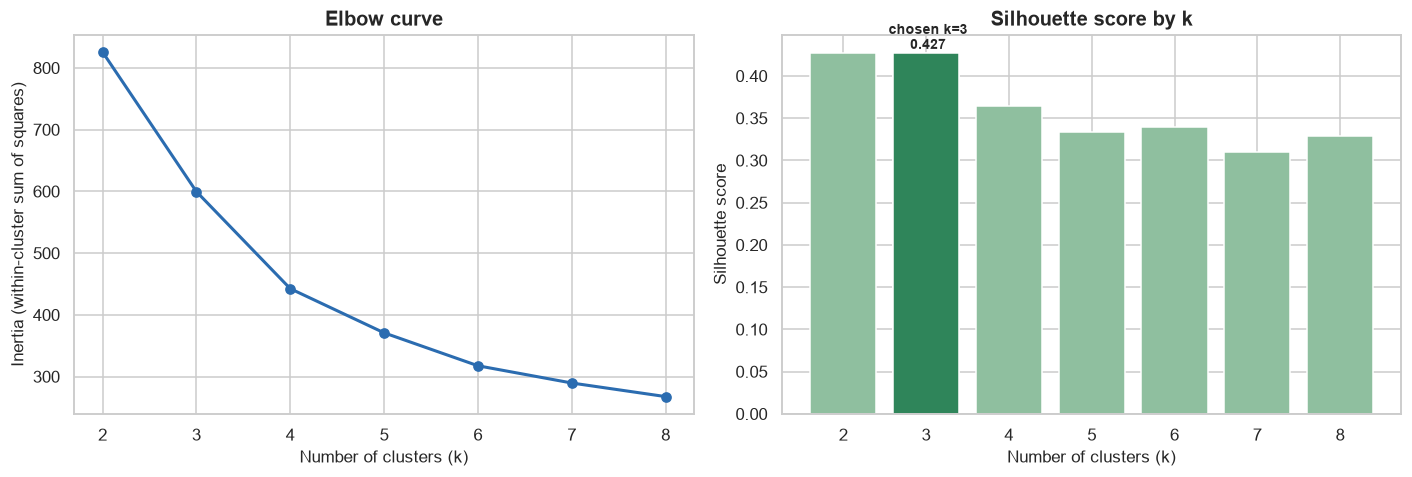

 k  Inertia  Silhouette
 2  825.743       0.427
 3  599.617       0.427
 4  442.402       0.364
 5  370.851       0.334
 6  317.499       0.340
 7  289.569       0.310
 8  267.555       0.329

Highest silhouette overall : k = 2 (0.427)
Selected k = 3 (highest silhouette among k >= 3 - a 2-way split is not actionable)


In [19]:
K_RANGE = range(2, 9)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels_km = km.fit_predict(X)
    rows.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(X, labels_km)})

elbow_df = pd.DataFrame(rows)
# k = 2 only separates "big spenders" from "small spenders", which is not an
# actionable segmentation, so the final k is chosen among k = 3..8.
candidates = elbow_df[elbow_df["k"] >= 3]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(elbow_df["k"], elbow_df["Inertia"], "o-", color="#2b6cb0", lw=2)
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_xticks(list(K_RANGE))

bars = axes[1].bar(elbow_df["k"], elbow_df["Silhouette"], color="#8fbf9f", edgecolor="white")
best_row = candidates.loc[candidates["Silhouette"].idxmax()]
overall_best_row = elbow_df.loc[elbow_df["Silhouette"].idxmax()]
axes[1].bar(best_row["k"], best_row["Silhouette"], color="#2f855a", edgecolor="white")
axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(list(K_RANGE))
axes[1].text(best_row["k"], best_row["Silhouette"], " chosen k={}\n {:.3f}".format(int(best_row["k"]), best_row["Silhouette"]),
             ha="center", va="bottom", fontsize=9, fontweight="bold")

fig.tight_layout()
save_chart("07_elbow_and_silhouette.png")
plt.show()

print(elbow_df.round(3).to_string(index=False))
best_k = int(best_row["k"])
print("\nHighest silhouette overall : k = {} ({:.3f})".format(int(overall_best_row["k"]), overall_best_row["Silhouette"]))
print("Selected k = {} (highest silhouette among k >= 3 - a 2-way split is not actionable)".format(best_k))

In [20]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
rfm["Cluster"] = kmeans.fit_predict(X)
final_silhouette = silhouette_score(X, rfm["Cluster"])

print("K-Means (k={}) fitted on log-transformed, scaled RFM".format(best_k))
print("Overall silhouette score: {:.3f}".format(final_silhouette))
print("\nCluster sizes:")
print(rfm["Cluster"].value_counts().sort_index().to_string())

K-Means (k=3) fitted on log-transformed, scaled RFM
Overall silhouette score: 0.427

Cluster sizes:
Cluster
0     68
1    173
2    279


### Profiling and naming the clusters

Clusters come back as numbers (0, 1, 2...). To make them business-readable we
rank them with a composite value score

> `Value score = z(Monetary) + z(Frequency) - z(Recency)`

and map the ranking onto clear names: **High-Value (Champions) -> Regular
(Loyal) -> ... -> Lowest Value (Lost)**.

In [21]:
def cluster_name_list(k):
    """Business names for k clusters, ordered best -> worst."""
    if k == 1:
        return ["High-Value (Champions)"]
    if k == 2:
        return ["High-Value (Champions)", "Low-Value (Lost)"]
    if k == 3:
        return ["High-Value (Champions)", "Regular (Loyal)", "Low-Value (Lost)"]
    middle_pool = ["New / Emerging", "Moderate (Occasional)", "Occasional (Light)",
                   "Low-Value (At Risk)", "Dormant / Lapsed"]
    n_middle = k - 3
    middle = middle_pool[len(middle_pool) - n_middle:]
    return ["High-Value (Champions)", "Regular (Loyal)"] + middle + ["Lowest Value (Lost)"]


def zscore(series):
    std = series.std(ddof=0)
    return (series - series.mean()) / (std if std else 1)


profile = (
    rfm.groupby("Cluster")
    .agg(Customers=("Customer_ID", "count"),
         Avg_Recency=("Recency", "mean"),
         Avg_Frequency=("Frequency", "mean"),
         Avg_Monetary=("Monetary", "mean"),
         Median_Monetary=("Monetary", "median"),
         Total_Revenue=("Monetary", "sum"))
    .reset_index()
)
profile["Value_Score"] = (zscore(profile["Avg_Monetary"])
                          + zscore(profile["Avg_Frequency"])
                          - zscore(profile["Avg_Recency"]))
profile = profile.sort_values("Value_Score", ascending=False).reset_index(drop=True)

name_map = dict(zip(profile["Cluster"], cluster_name_list(len(profile))))
profile["Cluster_Name"] = profile["Cluster"].map(name_map)
rfm["Cluster_Name"] = rfm["Cluster"].map(name_map)

profile["Share_of_Customers_%"] = (100 * profile["Customers"] / profile["Customers"].sum()).round(1)
profile["Share_of_Revenue_%"] = (100 * profile["Total_Revenue"] / profile["Total_Revenue"].sum()).round(1)
for col in ["Avg_Recency", "Avg_Frequency", "Avg_Monetary", "Median_Monetary", "Total_Revenue", "Value_Score"]:
    profile[col] = profile[col].round(1)

profile_out = profile[["Cluster", "Cluster_Name", "Customers", "Share_of_Customers_%",
                       "Avg_Recency", "Avg_Frequency", "Avg_Monetary", "Median_Monetary",
                       "Total_Revenue", "Share_of_Revenue_%", "Value_Score"]]
profile_out.to_csv(OUTPUTS / "cluster_profile.csv", index=False)
print("saved: outputs/cluster_profile.csv\n")
profile_out.to_markdown(index=False)

saved: outputs/cluster_profile.csv



'|   Cluster | Cluster_Name           |   Customers |   Share_of_Customers_% |   Avg_Recency |   Avg_Frequency |   Avg_Monetary |   Median_Monetary |    Total_Revenue |   Share_of_Revenue_% |   Value_Score |\n|----------:|:-----------------------|------------:|-----------------------:|--------------:|----------------:|---------------:|------------------:|-----------------:|---------------------:|--------------:|\n|         1 | High-Value (Champions) |         173 |                   33.3 |          43.1 |            15.3 |       127250   |           76350.7 |      2.20143e+07 |                 76.7 |           3.4 |\n|         0 | Regular (Loyal)        |          68 |                   13.1 |          23.5 |             2.5 |         9068.2 |            4741.3 | 616636           |                  2.1 |          -0.8 |\n|         2 | Low-Value (Lost)       |         279 |                   53.7 |         221.1 |             3.5 |        21721.8 |            9533   |      6.06038e+06 |

saved: outputs/charts/08_cluster_profile_heatmap.png


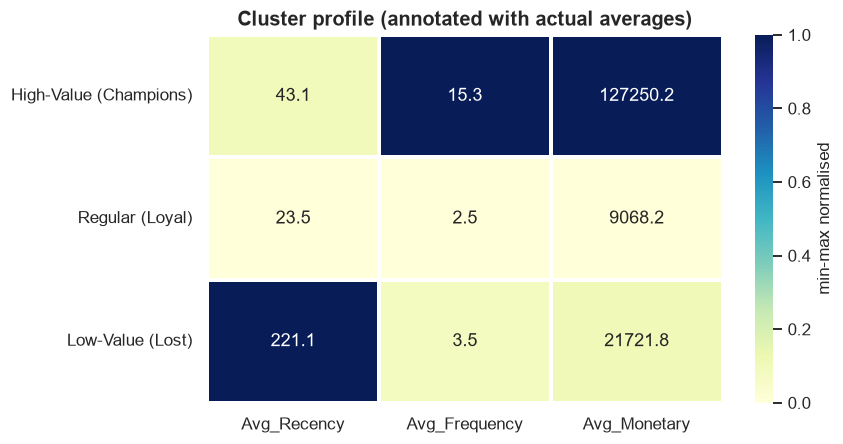

In [22]:
heat = profile.set_index("Cluster_Name")[["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]]
span = heat.max() - heat.min()
heat_norm = (heat - heat.min()) / span.replace(0, 1)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(heat_norm, annot=heat.values, fmt=".1f", cmap="YlGnBu",
            linewidths=1.5, linecolor="white", ax=ax,
            cbar_kws={"label": "min-max normalised"})
ax.set_title("Cluster profile (annotated with actual averages)")
ax.set_xlabel("")
ax.set_ylabel("")

fig.tight_layout()
save_chart("08_cluster_profile_heatmap.png")
plt.show()

saved: outputs/charts/09_cluster_scatter.png


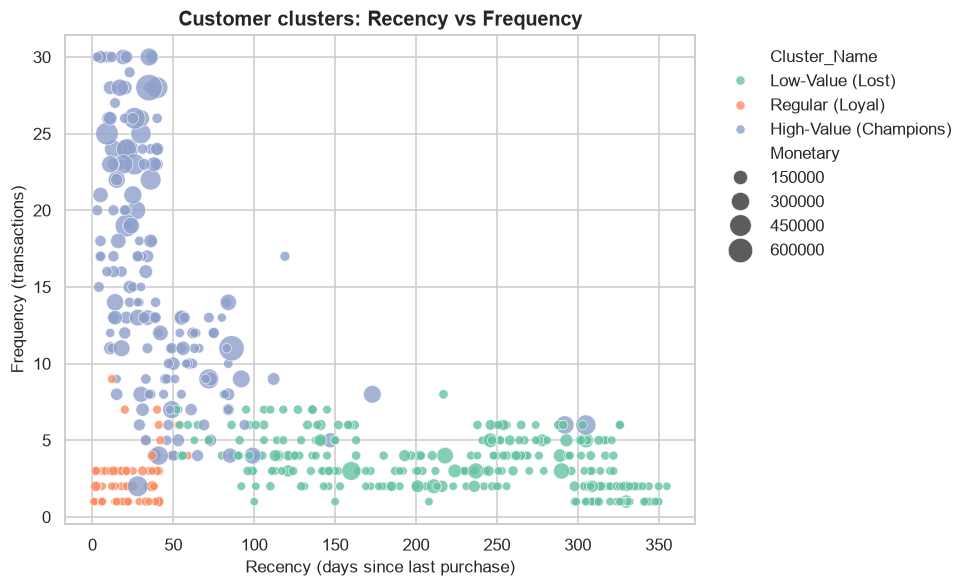

In [23]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=rfm, x="Recency", y="Frequency", hue="Cluster_Name",
                size="Monetary", sizes=(30, 300), palette="Set2", alpha=0.8, ax=ax)
ax.set_title("Customer clusters: Recency vs Frequency")
ax.set_xlabel("Recency (days since last purchase)")
ax.set_ylabel("Frequency (transactions)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="")

fig.tight_layout()
save_chart("09_cluster_scatter.png")
plt.show()

saved: outputs/charts/10_cluster_3d_scatter.png


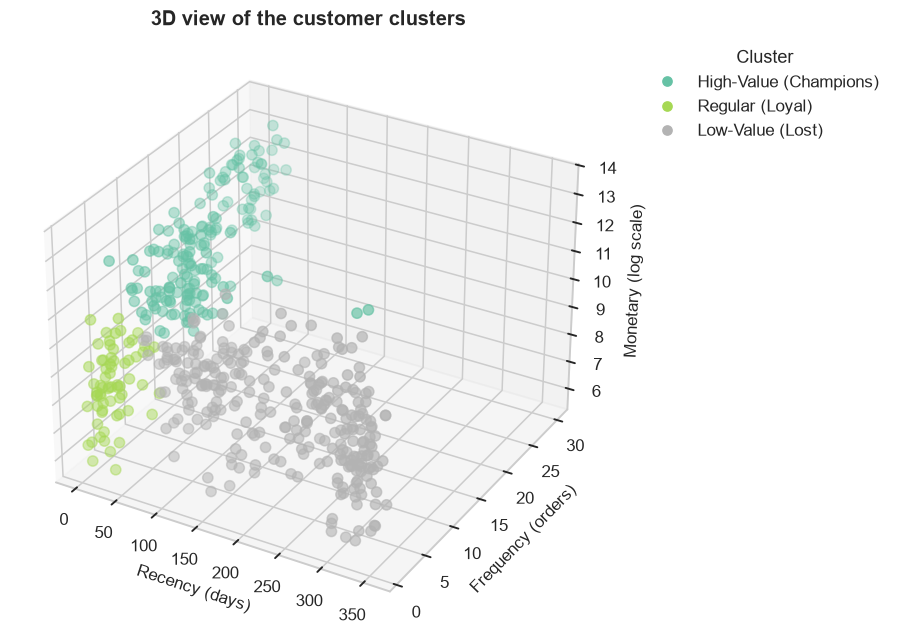

In [24]:
order_names = profile["Cluster_Name"].tolist()
codes = pd.Series(pd.Categorical(rfm["Cluster_Name"], categories=order_names).codes)
max_code = max(int(codes.max()), 1)

fig = plt.figure(figsize=(9.5, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(rfm["Recency"], rfm["Frequency"], np.log1p(rfm["Monetary"]),
           c=codes, cmap="Set2", vmin=0, vmax=max_code, s=45, alpha=0.85)
ax.set_xlabel("Recency (days)")
ax.set_ylabel("Frequency (orders)")
ax.set_zlabel("Monetary (log scale)")
ax.set_title("3D view of the customer clusters")

handles = [plt.Line2D([0], [0], marker="o", ls="", color=plt.cm.Set2(i / max_code), label=name)
           for i, name in enumerate(order_names)]
ax.legend(handles=handles, title="Cluster", loc="upper left", bbox_to_anchor=(1.05, 1))

fig.tight_layout()
save_chart("10_cluster_3d_scatter.png")
plt.show()

saved: outputs/charts/11_cluster_size_and_revenue.png


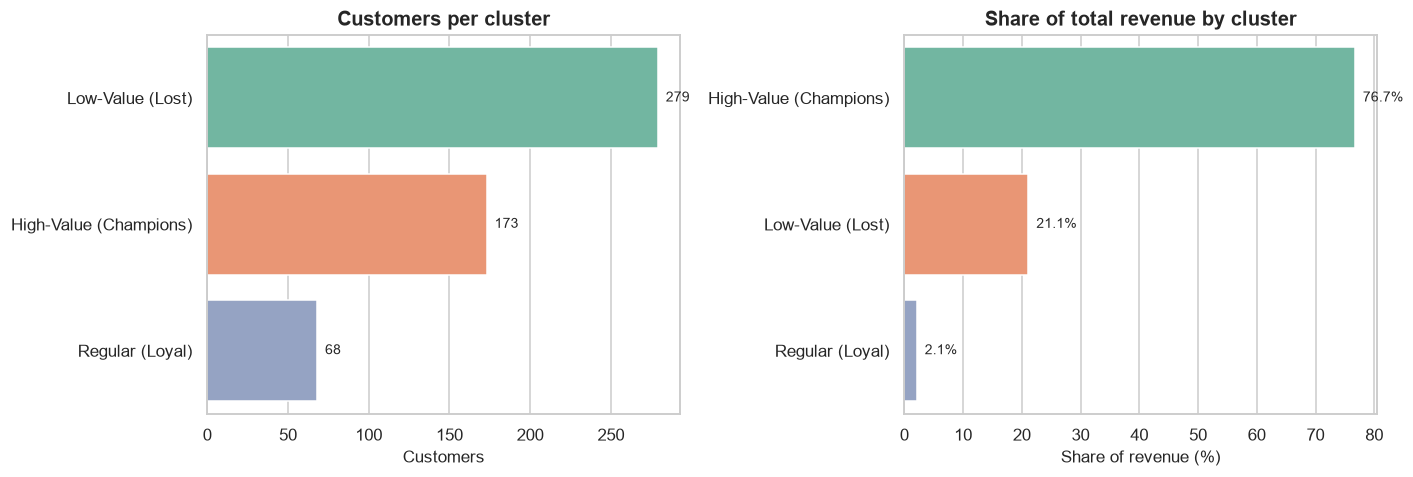

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

count_data = profile[["Cluster_Name", "Customers"]].sort_values("Customers", ascending=False)
rev_data = profile[["Cluster_Name", "Share_of_Revenue_%"]].sort_values("Share_of_Revenue_%", ascending=False)

sns.barplot(data=count_data, y="Cluster_Name", x="Customers", hue="Cluster_Name",
            palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Customers per cluster")
axes[0].set_xlabel("Customers")
axes[0].set_ylabel("")
for i, v in enumerate(count_data["Customers"]):
    axes[0].text(v, i, "  {:,}".format(v), va="center", fontsize=9)

sns.barplot(data=rev_data, y="Cluster_Name", x="Share_of_Revenue_%", hue="Cluster_Name",
            palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Share of total revenue by cluster")
axes[1].set_xlabel("Share of revenue (%)")
axes[1].set_ylabel("")
for i, v in enumerate(rev_data["Share_of_Revenue_%"]):
    axes[1].text(v, i, "  {:.1f}%".format(v), va="center", fontsize=9)

fig.tight_layout()
save_chart("11_cluster_size_and_revenue.png")
plt.show()

saved: outputs/charts/12_monetary_by_cluster.png


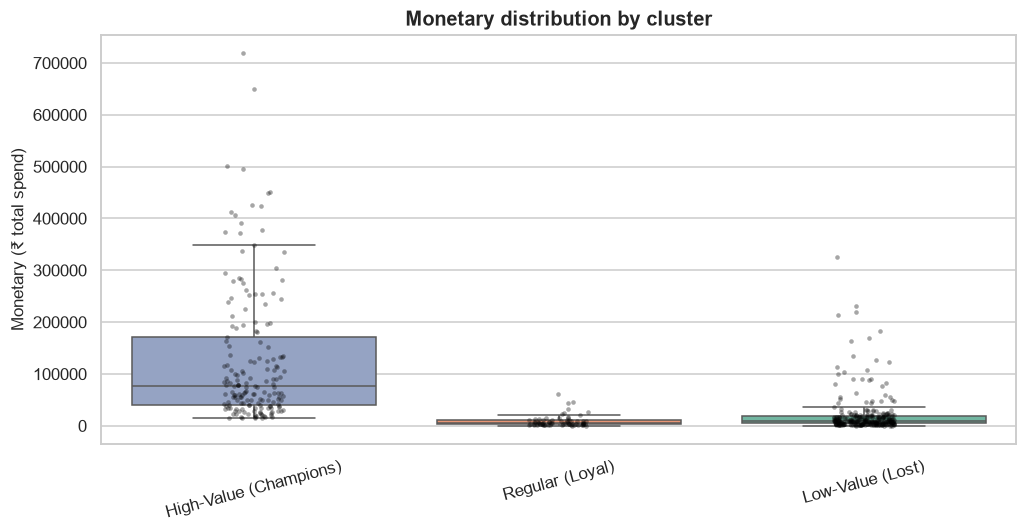

In [26]:
fig, ax = plt.subplots(figsize=(9.5, 5))
sns.boxplot(data=rfm, x="Cluster_Name", y="Monetary", order=order_names,
            hue="Cluster_Name", palette="Set2", legend=False, showfliers=False, ax=ax)
sns.stripplot(data=rfm, x="Cluster_Name", y="Monetary", order=order_names,
              color="black", size=3, alpha=0.35, ax=ax)
ax.set_title("Monetary distribution by cluster")
ax.set_xlabel("")
ax.set_ylabel("Monetary ({} total spend)".format(RUPEE))
ax.tick_params(axis="x", rotation=15)

fig.tight_layout()
save_chart("12_monetary_by_cluster.png")
plt.show()

## 9. High-value, regular and low-value customers

The model output is translated into three simple commercial tiers using the
`RFM_Score` (3 - 12):

| Tier | RFM_Score | Meaning |
| --- | --- | --- |
| **High-Value** | 10 - 12 | Recent, frequent and big spenders |
| **Regular** | 7 - 10 | Steady, average-value customers |
| **Low-Value** | 3 - 6 | Lapsed or one-off, low-spend customers |

The tiers are then cross-checked against the K-Means clusters: the more both
agree, the more confident the segmentation.

In [27]:
rfm["Customer_Tier"] = pd.cut(
    rfm["RFM_Score"], bins=[-np.inf, 6, 10, np.inf],
    labels=["Low-Value", "Regular", "High-Value"],
)

tier_order = ["High-Value", "Regular", "Low-Value"]
tier_summary = (
    rfm.groupby("Customer_Tier", observed=True)
    .agg(Customers=("Customer_ID", "count"),
         Avg_Recency=("Recency", "mean"),
         Avg_Frequency=("Frequency", "mean"),
         Avg_Monetary=("Monetary", "mean"),
         Total_Revenue=("Monetary", "sum"))
    .reindex(tier_order)
    .reset_index()
)
tier_summary["Share_of_Customers_%"] = (100 * tier_summary["Customers"] / tier_summary["Customers"].sum()).round(1)
tier_summary["Share_of_Revenue_%"] = (100 * tier_summary["Total_Revenue"] / tier_summary["Total_Revenue"].sum()).round(1)
for col in ["Avg_Recency", "Avg_Frequency", "Avg_Monetary", "Total_Revenue"]:
    tier_summary[col] = tier_summary[col].round(1)

tier_summary.to_csv(OUTPUTS / "tier_summary.csv", index=False)
print("saved: outputs/tier_summary.csv\n")
tier_summary.to_markdown(index=False)

saved: outputs/tier_summary.csv



'| Customer_Tier   |   Customers |   Avg_Recency |   Avg_Frequency |   Avg_Monetary |   Total_Revenue |   Share_of_Customers_% |   Share_of_Revenue_% |\n|:----------------|------------:|--------------:|----------------:|---------------:|----------------:|-----------------------:|---------------------:|\n| High-Value      |         106 |          26.7 |            18.9 |       154878   |     1.6417e+07  |                   20.4 |                 57.2 |\n| Regular         |         203 |         107.9 |             6.2 |        51713.1 |     1.04978e+07 |                   39   |                 36.6 |\n| Low-Value       |         211 |         217.9 |             2.5 |         8419.4 |     1.77649e+06 |                   40.6 |                  6.2 |'

saved: outputs/charts/13_customer_tiers.png


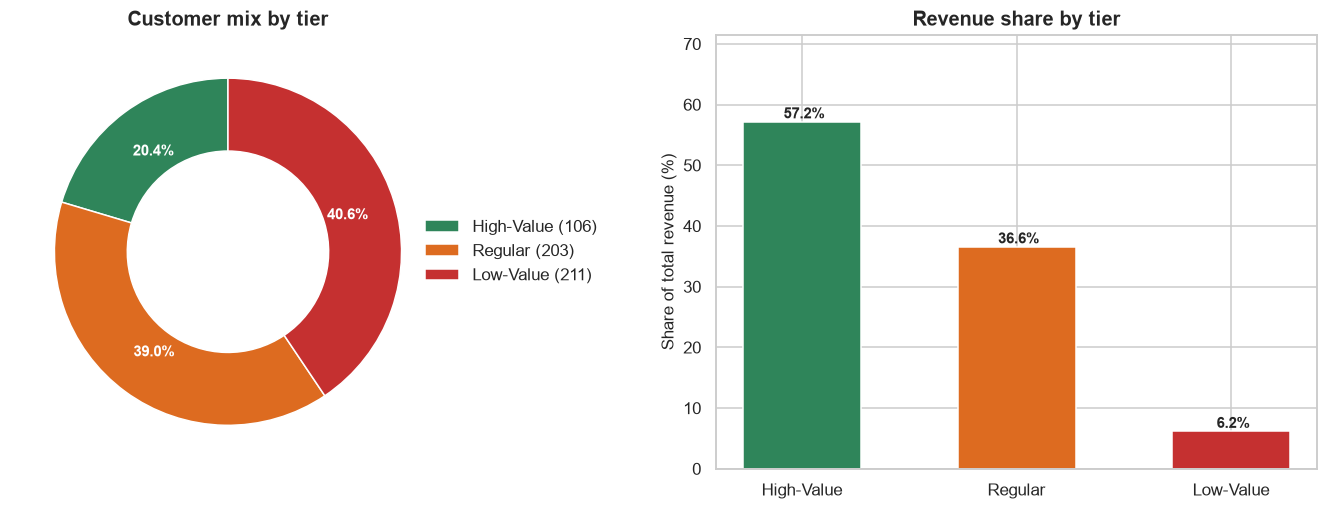

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

tier_colors = {"High-Value": "#2f855a", "Regular": "#dd6b20", "Low-Value": "#c53030"}
counts = tier_summary.set_index("Customer_Tier")["Customers"].reindex(tier_order)
wedges, _, autotexts = axes[0].pie(
    counts.values, labels=None, autopct="%1.1f%%", startangle=90,
    colors=[tier_colors[t] for t in counts.index], pctdistance=0.72,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    textprops={"fontsize": 10, "color": "white", "fontweight": "bold"},
)
axes[0].set_title("Customer mix by tier")
axes[0].legend(wedges, ["{} ({:,})".format(t, int(v)) for t, v in zip(counts.index, counts.values)],
               loc="center left", bbox_to_anchor=(0.92, 0.5))

rev = tier_summary.set_index("Customer_Tier")["Share_of_Revenue_%"].reindex(tier_order)
axes[1].bar(rev.index, rev.values, color=[tier_colors[t] for t in rev.index], width=0.55)
axes[1].set_title("Revenue share by tier")
axes[1].set_xlabel("")
axes[1].set_ylabel("Share of total revenue (%)")
axes[1].set_ylim(0, max(rev.values) * 1.25)
for i, (t, v) in enumerate(zip(rev.index, rev.values)):
    axes[1].text(i, v, " {:.1f}%".format(v), ha="center", va="bottom", fontsize=10, fontweight="bold")

fig.tight_layout()
save_chart("13_customer_tiers.png")
plt.show()

saved: outputs/charts/14_tier_vs_cluster_crosstab.png


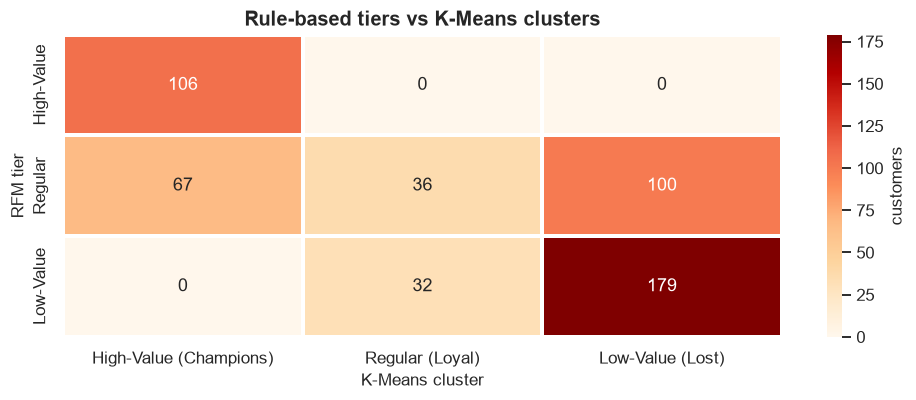

Agreement between tier and cluster (diagonal share):
  74.0% of customers sit in the dominant cluster of their tier


In [29]:
cross = pd.crosstab(rfm["Customer_Tier"], rfm["Cluster_Name"])[order_names]
cross = cross.reindex(tier_order)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(cross, annot=True, fmt="d", cmap="OrRd", linewidths=1.5,
            linecolor="white", ax=ax, cbar_kws={"label": "customers"})
ax.set_title("Rule-based tiers vs K-Means clusters")
ax.set_xlabel("K-Means cluster")
ax.set_ylabel("RFM tier")

fig.tight_layout()
save_chart("14_tier_vs_cluster_crosstab.png")
plt.show()

print("Agreement between tier and cluster (diagonal share):")
aligned = 0
for tier in tier_order:
    row = cross.loc[tier]
    if row.sum():
        aligned += row.max()
print("  {:.1f}% of customers sit in the dominant cluster of their tier".format(100 * aligned / cross.values.sum()))

In [30]:
rfm_export = rfm[["Customer_ID", "Recency", "Frequency", "Monetary",
                  "R_Score", "F_Score", "M_Score", "RFM_Score", "RFM_Segment",
                  "Cluster", "Cluster_Name", "Customer_Tier",
                  "Avg_Order_Value", "Distinct_Products", "Tenure_Days",
                  "First_Purchase", "Last_Purchase", "Categories"]].copy()

rfm.to_csv(OUTPUTS / "rfm_scores.csv", index=False)
rfm_export.to_csv(OUTPUTS / "customer_segments.csv", index=False)
print("saved: outputs/rfm_scores.csv")
print("saved: outputs/customer_segments.csv")

for tier in tier_order:
    subset = rfm_export[rfm_export["Customer_Tier"] == tier].sort_values("Monetary", ascending=False)
    filename = "customers_{}.csv".format(tier.lower().replace("-", "_"))
    subset.to_csv(OUTPUTS / filename, index=False)
    print("saved: outputs/{}  ({:,} customers, {} revenue)".format(
        filename, len(subset), money(subset["Monetary"].sum())))

cleaned.to_csv(OUTPUTS / "cleaned_transactions.csv", index=False)

saved: outputs/rfm_scores.csv
saved: outputs/customer_segments.csv
saved: outputs/customers_high_value.csv  (106 customers, ₹16,417,049 revenue)
saved: outputs/customers_regular.csv  (203 customers, ₹10,497,764 revenue)
saved: outputs/customers_low_value.csv  (211 customers, ₹1,776,492 revenue)


## 10. Business insights

Every sentence below is generated from the tables computed above - re-run the
notebook with new data and the insights update automatically.

In [31]:
top_cluster = profile.iloc[0]
bottom_cluster = profile.iloc[-1]
total_customers = len(rfm)
total_rev = rfm["Monetary"].sum()

hv = rfm[rfm["Customer_Tier"] == "High-Value"]
reg = rfm[rfm["Customer_Tier"] == "Regular"]
low = rfm[rfm["Customer_Tier"] == "Low-Value"]

at_risk = rfm[(rfm["Recency"] > 90) & (rfm["RFM_Score"] >= 7)]
champions = rfm[rfm["RFM_Segment"] == "Champions"]
lapsed = rfm[rfm["RFM_Segment"].isin(["Lost", "Hibernating"])]

top20_n = max(int(total_customers * 0.2), 1)
top20 = rfm.sort_values("Monetary", ascending=False).head(top20_n)
top20_share = 100 * top20["Monetary"].sum() / total_rev

hv_ids = set(hv["Customer_ID"])
hv_tx = cleaned[cleaned["Customer_ID"].isin(hv_ids)]
hv_cat = hv_tx.groupby("Category")["Total_Amount"].sum().sort_values(ascending=False)

insights = [
    "The dataset covers {:,} customers and {:,} transactions worth {} between {} and {}.".format(
        total_customers, len(cleaned), money(total_rev),
        date_min.strftime("%d %b %Y"), date_max.strftime("%d %b %Y")),
    "K-Means found {} customer clusters (k chosen by silhouette = {:.3f}); the model separated the "
    "customers cleanly with an overall silhouette of {:.3f}.".format(best_k, best_row["Silhouette"], final_silhouette),
    "The **{}** cluster holds {:.1f}% of customers ({:,}) but generates {:.1f}% of revenue ({}); "
    "they buy every {:.0f} days and spend {} on average.".format(
        top_cluster["Cluster_Name"], top_cluster["Share_of_Customers_%"], int(top_cluster["Customers"]),
        top_cluster["Share_of_Revenue_%"], money(top_cluster["Total_Revenue"]),
        top_cluster["Avg_Frequency"], money(top_cluster["Avg_Monetary"])),
    "The **{}** cluster is the opposite: {:.1f}% of customers ({:,}) contributing only {:.1f}% of revenue ({}), "
    "with an average gap of {:.0f} days since the last purchase.".format(
        bottom_cluster["Cluster_Name"], bottom_cluster["Share_of_Customers_%"], int(bottom_cluster["Customers"]),
        bottom_cluster["Share_of_Revenue_%"], money(bottom_cluster["Total_Revenue"]), bottom_cluster["Avg_Recency"]),
    "**High-Value customers** = {:,} people ({:.1f}% of the base) who drive {} - {:.1f}% of all revenue; "
    "they buy {:.1f} times a year and spend {} per order.".format(
        len(hv), 100 * len(hv) / total_customers, money(hv["Monetary"].sum()),
        100 * hv["Monetary"].sum() / total_rev, hv["Frequency"].mean(), money(hv["Avg_Order_Value"].mean())),
    "**Regular customers** = {:,} people ({:.1f}%) with {} revenue ({:.1f}%) - the volume engine of the business.".format(
        len(reg), 100 * len(reg) / total_customers, money(reg["Monetary"].sum()),
        100 * reg["Monetary"].sum() / total_rev),
    "**Low-Value customers** = {:,} people ({:.1f}%) producing just {} ({:.1f}% of revenue) - "
    "cheap to serve but not worth heavy discounting.".format(
        len(low), 100 * len(low) / total_customers, money(low["Monetary"].sum()),
        100 * low["Monetary"].sum() / total_rev),
    "Revenue is highly concentrated: the top 20% of customers by spend contribute {:.1f}% of total revenue "
    "(Pareto effect).".format(top20_share),
    "**{} customers are at risk of churn**: {:,} customers with a solid RFM score have not bought for more "
    "than 90 days - {} of revenue is exposed.".format(
        len(at_risk) > 0, len(at_risk), money(at_risk["Monetary"].sum())),
    "The RFM rules classify **{:,} Champions** ({:.1f}% of customers) worth {} and **{:,} Lost / Hibernating** "
    "customers worth {}.".format(
        len(champions), 100 * len(champions) / total_customers, money(champions["Monetary"].sum()),
        len(lapsed), money(lapsed["Monetary"].sum())),
    "High-Value customers prefer **{}** ({}), **{}** ({}) and **{}** ({}) - the categories to protect and "
    "cross-sell in.".format(
        hv_cat.index[0], money(hv_cat.iloc[0]),
        hv_cat.index[1], money(hv_cat.iloc[1]),
        hv_cat.index[2], money(hv_cat.iloc[2])),
    "Average recency across the base is {:.0f} days, but the clusters range from {:.0f} days (best) to "
    "{:.0f} days (worst) - a clear retention gap.".format(
        rfm["Recency"].mean(), profile["Avg_Recency"].min(), profile["Avg_Recency"].max()),
]

print("=== KEY INSIGHTS ===\n")
for i, text in enumerate(insights, 1):
    print("{}. {}".format(i, text.replace("**", "")))

=== KEY INSIGHTS ===

1. The dataset covers 520 customers and 3,797 transactions worth ₹28,691,305 between 01 Jan 2025 and 26 Dec 2025.
2. K-Means found 3 customer clusters (k chosen by silhouette = 0.427); the model separated the customers cleanly with an overall silhouette of 0.427.
3. The High-Value (Champions) cluster holds 33.3% of customers (173) but generates 76.7% of revenue (₹22,014,289); they buy every 15 days and spend ₹127,250 on average.
4. The Low-Value (Lost) cluster is the opposite: 53.7% of customers (279) contributing only 21.1% of revenue (₹6,060,380), with an average gap of 221 days since the last purchase.
5. High-Value customers = 106 people (20.4% of the base) who drive ₹16,417,049 - 57.2% of all revenue; they buy 18.9 times a year and spend ₹8,915 per order.
6. Regular customers = 203 people (39.0%) with ₹10,497,764 revenue (36.6%) - the volume engine of the business.
7. Low-Value customers = 211 people (40.6%) producing just ₹1,776,492 (6.2% of revenue) - cheap

In [32]:
recommendations = [
    "PROTECT the {:,} High-Value customers ({} revenue): run a tiered loyalty / VIP programme, "
    "early access and a dedicated service line - losing one of them costs on average {}.".format(
        len(hv), money(hv["Monetary"].sum()), money(hv["Monetary"].mean())),
    "RE-ENGAGE the {:,} at-risk customers ({}): they bought often and recently enough to be valuable - "
    "trigger win-back email/SMS flows after {:.0f} days of inactivity with a personalised offer.".format(
        len(at_risk), money(at_risk["Monetary"].sum()), 90),
    "GROW the {:,} Regular customers ({} revenue) into High-Value with second-purchase incentives, "
    "bundle offers and category recommendations based on their favourite category.".format(
        len(reg), money(reg["Monetary"].sum())),
    "NURTURE the {:,} Recent / New customers while they are still warm - a 7-14 day onboarding sequence "
    "is the cheapest way to lift their frequency.".format(
        len(rfm[rfm["RFM_Segment"] == "Recent / New Customers"])),
    "DEPRIORITISE deep discounting for the {:,} Low-Value customers (only {:.1f}% of revenue): "
    "keep servicing costs low and let automation do the work.".format(
        len(low), 100 * low["Monetary"].sum() / total_rev),
    "MERCHANDISE around the winners: {} and {} generate the most revenue from High-Value customers - "
    "feature them in campaigns, home page and bundles.".format(hv_cat.index[0], hv_cat.index[1]),
    "RE-WIN the {:,} Lost / Hibernating customers ({}) with a single, high-impact comeback offer; "
    "if they do not respond, suppress them from paid channels.".format(
        len(lapsed), money(lapsed["Monetary"].sum())),
    "MONITOR the segment health monthly: track cluster sizes, average recency and the tier mix, "
    "and re-run this notebook when the mix shifts by more than 5 points.",
]

print("=== RECOMMENDATIONS ===\n")
for i, text in enumerate(recommendations, 1):
    print("{}. {}".format(i, text))

=== RECOMMENDATIONS ===

1. PROTECT the 106 High-Value customers (₹16,417,049 revenue): run a tiered loyalty / VIP programme, early access and a dedicated service line - losing one of them costs on average ₹154,878.
2. RE-ENGAGE the 93 at-risk customers (₹5,997,421): they bought often and recently enough to be valuable - trigger win-back email/SMS flows after 90 days of inactivity with a personalised offer.
3. GROW the 203 Regular customers (₹10,497,764 revenue) into High-Value with second-purchase incentives, bundle offers and category recommendations based on their favourite category.
4. NURTURE the 38 Recent / New customers while they are still warm - a 7-14 day onboarding sequence is the cheapest way to lift their frequency.
5. DEPRIORITISE deep discounting for the 211 Low-Value customers (only 6.2% of revenue): keep servicing costs low and let automation do the work.
6. MERCHANDISE around the winners: Electronics and Clothing generate the most revenue from High-Value customers - f

In [33]:
report_path = REPORTS_DIR / "analysis_report.md"

report = []
report.append("# Customer Segmentation Analysis - Report")
report.append("")
report.append("**Data Analytics Internship - Task 2**")
report.append("")
report.append("## 1. Dataset overview")
report.append("")
report.append("| Metric | Value |")
report.append("| --- | --- |")
report.append("| Source | data/customer_purchases.csv |")
report.append("| Rows after cleaning | {:,} of {:,} |".format(len(cleaned), len(raw)))
report.append("| Customers | {:,} |".format(total_customers))
report.append("| Period | {} - {} |".format(date_min.strftime("%d %b %Y"), date_max.strftime("%d %b %Y")))
report.append("| Revenue | {} |".format(money(total_rev)))
report.append("| Average order value | {} |".format(money(cleaned["Total_Amount"].mean())))
report.append("| Snapshot date used for RFM | {} |".format(snapshot.strftime("%d %b %Y")))
report.append("")
report.append("## 2. Data cleaning")
report.append("")
report.append(cleaning_report.to_markdown(index=False))
report.append("")
report.append("## 3. RFM segments (rule based)")
report.append("")
report.append(seg_summary.to_markdown(index=False))
report.append("")
report.append("## 4. K-Means clusters")
report.append("")
report.append("- Features: Recency, Frequency, Monetary - log transformed (`log1p`) and standardised")
report.append("- k selected by elbow curve + silhouette (tested 2-8): **k = {}**".format(best_k))
report.append("- Overall silhouette score: **{:.3f}**".format(final_silhouette))
report.append("")
report.append(profile_out.to_markdown(index=False))
report.append("")
report.append("## 5. Customer tiers")
report.append("")
report.append(tier_summary.to_markdown(index=False))
report.append("")
report.append("## 6. Key insights")
report.append("")
for i, text in enumerate(insights, 1):
    report.append("{}. {}".format(i, text))
report.append("")
report.append("## 7. Recommendations")
report.append("")
for i, text in enumerate(recommendations, 1):
    report.append("{}. {}".format(i, text))
report.append("")
report.append("## 8. Outputs")
report.append("")
report.append("- `outputs/rfm_scores.csv` - RFM metrics, scores, segments, clusters, tiers")
report.append("- `outputs/customer_segments.csv` - the segment table shared with the business")
report.append("- `outputs/customers_high_value.csv`, `customers_regular.csv`, `customers_low_value.csv` - tier lists")
report.append("- `outputs/cluster_profile.csv`, `outputs/rfm_segment_summary.csv`, `outputs/tier_summary.csv`")
report.append("- `outputs/charts/*.png` - all visualisations")
report.append("")

with open(report_path, "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))

print("saved: outputs/reports/analysis_report.md")
print("\n=== TIER SUMMARY ===")
print(tier_summary.to_string(index=False))

saved: outputs/reports/analysis_report.md

=== TIER SUMMARY ===
Customer_Tier  Customers  Avg_Recency  Avg_Frequency  Avg_Monetary  Total_Revenue  Share_of_Customers_%  Share_of_Revenue_%
   High-Value        106         26.7           18.9      154877.8     16417049.3                  20.4                57.2
      Regular        203        107.9            6.2       51713.1     10497763.7                  39.0                36.6
    Low-Value        211        217.9            2.5        8419.4      1776492.2                  40.6                 6.2


## 11. Conclusion

The customer base splits into clearly separated behavioural groups: a small,
high-value core that carries most of the revenue, a broad regular middle that
provides volume, and a long tail of lapsed or one-off buyers. The rule-based
RFM tiers and the K-Means clusters agree on the overall shape of the base, so
the segmentation can be used with confidence for campaign targeting.

**Business takeaway:** retention beats acquisition here - protecting the
high-value core and win-back of at-risk customers is worth more than
discounting the low-value tail.

---

### Project structure

```
customer-segmentation/
├── data/customer_purchases.csv        # purchase dataset (year of transactions)
├── notebooks/customer_segmentation.ipynb
├── outputs/
│   ├── charts/*.png                   # 14 generated charts
│   ├── reports/
│   │   ├── data_cleaning_report.txt
│   │   └── analysis_report.md
│   ├── cleaned_transactions.csv
│   ├── rfm_scores.csv
│   ├── customer_segments.csv
│   ├── customers_high_value.csv / customers_regular.csv / customers_low_value.csv
│   ├── cluster_profile.csv
│   ├── rfm_segment_summary.csv
│   └── tier_summary.csv
├── src/generate_dataset.py            # reproducible dataset generator
├── requirements.txt
└── README.md
```

### How to run

```bash
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute notebooks/customer_segmentation.ipynb --inplace
```

Or open it interactively: `jupyter notebook notebooks/customer_segmentation.ipynb`